### SeRNN block taken for our approach :

#### Block 1 — Imports

Taken from the demo (cells 3, 4, 5). Removed: `to_categorical`, which the demo imports but never uses.

In [15]:
# [DEMO cells 3 + 5]
import os                                          # used by block 6 (outputs folder)
import numpy as np
import pandas as pd                                # used by mazeGeneratorI
import scipy.spatial.distance                      # used by SE1 (distance matrix)
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D           # used by SE1.visualise_neuron_structure
import tensorflow as tf
import tensorflow.keras as keras
from tensorflow.keras.regularizers import Regularizer
from tensorflow.python.keras import backend       # used by SE1 (backend.cast_to_floatx)

# [DEMO cell 4] versions, should match requirements.txt
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| numpy", np.__version__)

tensorflow 2.21.0 | keras 3.15.0 | numpy 2.2.6


#### Block 2 — Hyperparameters

Every argument the demo passes, in one place. Source tags: `[DEMO cell N]` = seRNN_demo.ipynb

In [ ]:
# Seeds [DEMO cell 6]
NP_SEED = 1829         # numpy seed 
TF_SEED = 9492         # tensorflow seed

# Task: one-step inference maze [DEMO cell 11]
GOAL_STEPS = 20        # goal presentation
DELAY_STEPS = 10       # delay
CHOICE_STEPS = 20      # choices presentation
N_TRAIN = 5120         # problems per epoch
N_TEST = 2560
N_VAL = 2560
BATCH_SIZE = 128

# Network [DEMO cell 21]
N_UNITS = 100
GRID = (5, 5, 4)       # SE1 default network_structure: 100 units on a 5x5x4 grid
INPUT_NOISE_STD = 0.05
N_OUT = 4              # Dense(4): 4 directions (Left, Up, Right, Down)

# Training [DEMO cell 23-24] : Adam with default parameters (lr 0.001), 10 epochs
EPOCHS = 10

# Regularisation strength γ. TO BE AWARE Because:
#   0.5 [DEMO cell 20] · 0.3 [CAPSULE seRNN_demo] · 0.08 [PAPER Fig. 2e, example network]
GAMMA_SERNN = 0.22     # Fig. 6c sweet-spot centre: 22 % of linspace(1e-6, 1, 1001)
GAMMA_L1 = 0.0066      # same position: 22 % of linspace(1e-7, 0.03, 1001)

# Selection PAPER: keep networks with accuracy > 90 %
ACC_MIN = 0.9
# 10 networks per group, one seed each. Each list = the first 10 seeds (in 0..31) whose network passes ACC_MIN
# Seeds are not paired across groups, as in the paper.
SEEDS = {'seRNN': [2, 5, 7, 10, 11, 13, 15, 22, 25, 31],
         'L1':    [1, 7, 8, 9, 10, 11, 12, 13, 18, 19]}

# Where results are written
OUT_DIR = "outputs"

# [DEMO cell 6]
np.random.seed(NP_SEED)
tf.random.set_seed(TF_SEED)
tf.config.experimental.enable_op_determinism()

#### Block 3 — Task: the 16 problems

The demo trains on 8 problems, the paper's *regular* task. The paper lists all 16 possible problems in Extended Data Table 1 ("harder version", Supp. Fig. 8). Stimulus A = goal, stimulus B = 2 possible directions, correct choice = the direction that moves closer to the goal.

Block 3a = the demo generator with 2 changes, marked `MODIFIED`: the problem list (16 instead of 8) and `randint(0, 8)` → `randint(0, 16)`. Same encoding: 8 inputs, 4 outputs.

Block 3b = build the datasets [DEMO cells 11–12] and look at them.

In [17]:
# [DEMO cell 9] mazeGeneratorI, copied as is except the lines marked MODIFIED (16 problems instead of 8)
class mazeGeneratorI():
    '''
    Objects of the mazeGeneratorI class can create numpy and tf datasets of the first choice of the maze task.
    Task structure:
        Goal presentation, followed by delay period, followed by choice options.
    Response:
        One response required from agent at end of episode. Direction (Left, Up, Right, Down) of first step.
    Encoding:
        Both observations and labels are OneHot encoded.
    Usage:
        The two only function a user should need to access are "construct_numpy_data" and "construct_tf_data"
    Options:
        Both data construction methods have an option to shuffle the labels of data.
        The numpy data construction method allows to also return the maze identifiers.
    '''
    def __init__(self, goal_presentation_steps, delay_steps, choices_presentation_steps):
        self.version = 'v1.2.0'

        # Import variables defining episode
        self.goal_presentation_steps = goal_presentation_steps
        self.delay_steps = delay_steps
        self.choices_presentation_steps = choices_presentation_steps

        # Construct mazes dataframe
        ## Add encoded versions of the goal / choices presentations and the next step response
        self.mazesdf = self.import_maze_dic()
        self.mazesdf['Goal_Presentation'] = self.mazesdf['goal'].map({
            7:np.concatenate((np.array([1,0,0,0]),np.repeat(0,4))),
            9:np.concatenate((np.array([0,1,0,0]),np.repeat(0,4))),
            17:np.concatenate((np.array([0,0,1,0]),np.repeat(0,4))),
            19:np.concatenate((np.array([0,0,0,1]),np.repeat(0,4)))})
        self.mazesdf['Choices_Presentation']=self.mazesdf['ChoicesCategory'].map(lambda x: self.encode_choices(x=x))
        self.mazesdf['Step_Encoded']=self.mazesdf['NextFPmap'].map(lambda x: self.encode_next_step(x=x))

    def construct_numpy_data(self, number_of_problems, return_maze_identifiers = False, np_shuffle_data = False):
        # Create a new column which hold the vector for each problem
        self.mazesdf['Problem_Vec']=self.mazesdf.apply(lambda x: self.create_problem_observation(row= x,goal_presentation_steps= self.goal_presentation_steps,delay_steps= self.delay_steps,choices_presentation_steps= self.choices_presentation_steps), axis=1)
        # Set a random order of maze problems for the current session
        self.mazes_order = np.random.randint(0,len(self.mazesdf),number_of_problems)   # MODIFIED: was randint(0,8,...)

        # Create vectors, holding observations and labels
        session_observation =np.array([])
        session_labels = np.array([])
        for i in self.mazes_order:
            session_observation = np.append(session_observation,self.mazesdf.iloc[i]['Problem_Vec'])
            session_labels = np.append(session_labels,self.mazesdf.iloc[i]['Step_Encoded'])

        # Reshape vectors to fit network observation and response space
        session_length = self.goal_presentation_steps + self.delay_steps + self.choices_presentation_steps
        session_observation = np.reshape(session_observation, (-1,session_length,8)).astype('float32')
        session_labels = np.reshape(session_labels, (-1,4)).astype('float32')

        # If np_shuffle_data == 'Labels, the order of labels is shuffled to randomise correct answers
        if np_shuffle_data == 'Labels':
          shuffle_generator = np.random.default_rng(38446)
          shuffle_generator.shuffle(session_labels,axis=0)

        # If return_maze_identifiers == 'IDs', return the array with maze IDs alongside the regular returns (observations, labels)
        if return_maze_identifiers == 'IDs':
          return session_observation, session_labels, self.mazes_order

        return session_observation, session_labels

    def construct_tf_data(self, number_of_problems, batch_size, tf_shuffle_data = False):
        # Create dataset as described by numpy dataset function and transform it into a TF dataset
        npds, np_labels = self.construct_numpy_data(number_of_problems=number_of_problems, np_shuffle_data = tf_shuffle_data)
        tfdf = tf.data.Dataset.from_tensor_slices((npds, np_labels))
        tfdf = tfdf.batch(batch_size)
        return tfdf

    def reset_construction_params(self, goal_presentation_steps, delay_steps, choices_presentation_steps):
        self.goal_presentation_steps = goal_presentation_steps
        self.delay_steps = delay_steps
        self.choices_presentation_steps = choices_presentation_steps

    def import_maze_dic(self, mazeDic=None):
        if mazeDic == None:
            # Set up dataframe with first choices of maze task
            ## The dictionary was generated using MazeMetadata.py (v1.0.0) and the following call:
            ### mazes.loc[(mazes['Nsteps']==2)&(mazes['ChoiceNo']=='ChoiceI')][['goal','ChoicesCategory','NextFPmap']].reset_index(drop=True).to_dict()
            # MODIFIED: the 16 problems of [PAPER Extended Data Table 1] instead of the demo's 8.
            # Goal codes as in the demo: 9 = (Right, up), 19 = (Right, down), 7 = (Left, up), 17 = (Left, down).
            # Order = ED Table 1 problems 1..16. Regular task (the demo's 8) = problems 2, 4, 5, 8, 9, 12, 14, 16.
            self.mazesDic = {'goal': {0: 9, 1: 9, 2: 9, 3: 9, 4: 19, 5: 19, 6: 19, 7: 19,
                                      8: 7, 9: 7, 10: 7, 11: 7, 12: 17, 13: 17, 14: 17, 15: 17},
            'ChoicesCategory': {0: 'lr', 1: 'rd', 2: 'ud', 3: 'ul',
                                4: 'lr', 5: 'ur', 6: 'ud', 7: 'ld',
                                8: 'lr', 9: 'ld', 10: 'ud', 11: 'ur',
                                12: 'lr', 13: 'ul', 14: 'ud', 15: 'rd'},
            'NextFPmap': {0: 'r', 1: 'r', 2: 'u', 3: 'u',
                          4: 'r', 5: 'r', 6: 'd', 7: 'd',
                          8: 'l', 9: 'l', 10: 'u', 11: 'u',
                          12: 'l', 13: 'l', 14: 'd', 15: 'd'}}
        else:
            self.mazesDic = mazesDic

        # Create and return dataframe
        return pd.DataFrame(self.mazesDic)

    def encode_choices(self, x):
        # Helper function to create the observation vector for choice periods
        choices_sec = np.repeat(0,4)
        choicesEncoding = pd.Series(list(x))
        choicesEncoding = choicesEncoding.map({'l':1,'u':2,'r':3,'d':4})
        for encodedChoice in choicesEncoding:
            choices_sec[encodedChoice-1]=1
        return np.concatenate((np.repeat(0,4),choices_sec))

    def encode_next_step(self, x):
        # Helper function to change the response / action to a OneHot encoded vector
        step_sec = np.repeat(0,4)
        stepEncoding = pd.Series(list(x))
        stepEncoding = stepEncoding.map({'l':1,'u':2,'r':3,'d':4})
        for encodedStep in stepEncoding:
            step_sec[encodedStep-1]=1
        return step_sec

    def create_problem_observation(self, row, goal_presentation_steps, delay_steps, choices_presentation_steps):
        # Helper function to create one vector describing the entire outline of one maze problem (Goal presentation, Delay Period, and Choices Presentation)
        goal_vec = np.tile(row['Goal_Presentation'], goal_presentation_steps)
        delay_vec = np.tile(np.repeat(0,8), delay_steps)
        choices_vec = np.tile(row['Choices_Presentation'], choices_presentation_steps)
        problem_vec = np.concatenate((goal_vec,delay_vec,choices_vec))
        return problem_vec

    def __repr__(self):
        return '\n'.join([
            f'Maze DataSet Generator',
            f'Goal Presentation Steps: {self.goal_presentation_steps}',
            f'Delay Steps: {self.delay_steps}',
            f'Choices Presentation Steps: {self.choices_presentation_steps}'])


train: times each of the 16 problems is drawn: [334 310 340 315 311 324 355 331 332 305 310 302 329 305 309 308]


,goal (stimulus A),choices (stimulus B),correct answer,in demo (regular task)
problem,,,,
1,right-up,left / right,right,False
2,right-up,right / down,right,True
3,right-up,up / down,up,False
4,right-up,up / left,up,True
5,right-down,left / right,right,True
6,right-down,up / right,right,False
7,right-down,up / down,down,False
8,right-down,left / down,down,True
9,left-up,left / right,left,True


inputs (128, 50, 8) | labels (128, 4)


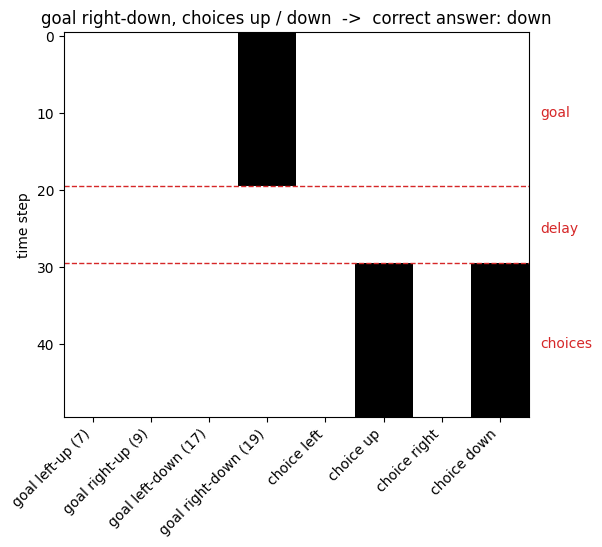

In [18]:
# [DEMO cell 11] build the datasets
np.random.seed(NP_SEED)   # re-seed here: the datasets depend on numpy's random state, so re-running this cell
                          # (or running cells out of order) must always give the same data
gen = mazeGeneratorI(goal_presentation_steps=GOAL_STEPS, delay_steps=DELAY_STEPS, choices_presentation_steps=CHOICE_STEPS)
tfdf = gen.construct_tf_data(number_of_problems=N_TRAIN, batch_size=BATCH_SIZE)
print("train: times each of the 16 problems is drawn:", np.bincount(gen.mazes_order, minlength=16))
tfdf_test = gen.construct_tf_data(number_of_problems=N_TEST, batch_size=BATCH_SIZE)
tfdf_val = gen.construct_tf_data(number_of_problems=N_VAL, batch_size=BATCH_SIZE)

# Readable names for the demo encoding (mazeGeneratorI.__init__).
# Goal codes = cells of a 5x5 maze numbered 1..25 row by row; the agent starts at the centre cell 13.
GOAL_NAMES = {7: 'left-up', 9: 'right-up', 17: 'left-down', 19: 'right-down'}
DIR_NAMES = {'l': 'left', 'u': 'up', 'r': 'right', 'd': 'down'}
INPUT_NAMES = ['goal left-up (7)', 'goal right-up (9)', 'goal left-down (17)', 'goal right-down (19)',
               'choice left', 'choice up', 'choice right', 'choice down']

# The 16 problems, as in [PAPER Extended Data Table 1]
problems = pd.DataFrame({
    'problem': range(1, 17),
    'goal (stimulus A)': gen.mazesdf['goal'].map(GOAL_NAMES),
    'choices (stimulus B)': gen.mazesdf['ChoicesCategory'].map(lambda s: ' / '.join(DIR_NAMES[c] for c in s)),
    'correct answer': gen.mazesdf['NextFPmap'].map(DIR_NAMES),
    'in demo (regular task)': [p in (2, 4, 5, 8, 9, 12, 14, 16) for p in range(1, 17)]})
display(problems.set_index('problem'))   # problem number = row label (no extra 0..15 index)

# [DEMO cell 12] one batch: inputs (batch, time steps, 8), labels (batch, 4)
example_data = next(iter(tfdf))
print("inputs", example_data[0].shape, "| labels", example_data[1].shape)

# One example trial. Rows = time steps, columns = the 8 inputs. Black = 1, white = 0.
x, y = example_data[0][0].numpy(), example_data[1][0].numpy()
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(x, aspect='auto', cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
ax.set_xticks(range(8)); ax.set_xticklabels(INPUT_NAMES, rotation=45, ha='right')
ax.set_ylabel('time step')
for t in (GOAL_STEPS, GOAL_STEPS + DELAY_STEPS):
    ax.axhline(t - 0.5, color='tab:red', lw=1, ls='--')
for t0, t1, name in [(0, GOAL_STEPS, 'goal'), (GOAL_STEPS, GOAL_STEPS + DELAY_STEPS, 'delay'),
                     (GOAL_STEPS + DELAY_STEPS, GOAL_STEPS + DELAY_STEPS + CHOICE_STEPS, 'choices')]:
    ax.text(7.7, (t0 + t1) / 2, name, va='center', color='tab:red')
goal = INPUT_NAMES[x[0, :4].argmax()].split(' ')[1]
choices = [INPUT_NAMES[4 + k].split(' ')[1] for k in np.flatnonzero(x[-1, 4:])]
ax.set_title(f"goal {goal}, choices {' / '.join(choices)}  ->  correct answer: {['left', 'up', 'right', 'down'][y.argmax()]}")
plt.show()

#### Block 4 — Regularisers

Both regularisers act on `W_rec` only (the 100 × 100 recurrent weights).

- **seRNN** [DEMO cells 15–16], copied as is. `SE1` places the 100 units on a 5 × 5 × 4 grid and builds the distance matrix D. `SE1_sWc` (the one used for seRNNs) adds the communicability C. Penalty = γ · Σ |W| ⊙ D ⊙ C.
- **L1** [CAPSULE recording_decoding_demo, cell 8]: `tf.keras.regularizers.L1(γ)`. Penalty = γ · Σ |W|.

Block 4a = the two demo classes. Block 4b = build both regularisers and look at the grid and at D.

In [19]:
# [DEMO cell 15] SE1: L1 weighted by distance.
class SE1(Regularizer):
  """A regulariser for sptially embedded RNNs.
  Applies L1 regularisation to recurrent kernel of
  RNN which is weighted by the distance of units
  in predefined 3D space.
  Calculation:
      se1 * sum[distance_matrix o recurrent_kernel]
  Attributes:
      se1: Float; Weighting of SE1 regularisation term.
      distance_tensor: TF tensor / matrix with cost per
      connection in weight matrix of network.
  """

  def __init__(self, se1=0.01, neuron_num = 100, network_structure = (5,5,4), coordinates_list = None, distance_power = 1, distance_metric = 'euclidean'):
    self.version = 'v1.1.0'
    self.distance_power = distance_power

    # Set SE1 regularisation strength to default of 0.01 if no value given
    se1 = 0.01 if se1 is None else se1
    self._check_penalty_number(se1)

    # Transform regularisation strength to TF's standard float format
    self.se1 = backend.cast_to_floatx(se1)

    # Set up tensor with distance matrix
    ## Set up neurons per dimension
    nx = np.arange(network_structure[0])
    ny = np.arange(network_structure[1])
    nz = np.arange(network_structure[2])

    ## Set up coordinate grid
    [x,y,z] = np.meshgrid(nx,ny,nz)
    self.coordinates = [x.ravel(),y.ravel(),z.ravel()]

    ## Override coordinate grid if one if provided in init
    if coordinates_list!=None:
      self.coordinates = coordinates_list

    ## Check neuron number / number of coordinates
    if (len(self.coordinates[0])==neuron_num)&(len(self.coordinates[1])==neuron_num)&(len(self.coordinates[2])==neuron_num):
      pass
    else:
      raise ValueError('Network / coordinate structure does not match the number of neurons.')

    ## Calculate the euclidean distance matrix
    euclidean_vector = scipy.spatial.distance.pdist(np.transpose(self.coordinates), metric=distance_metric)
    euclidean = scipy.spatial.distance.squareform(euclidean_vector**self.distance_power)
    self.distance_matrix = euclidean.astype('float32')
    self.spatial_cost_matrix = self.distance_matrix

    ## Add minimal cost for recurrent self connection (on diagonal)
    #diag_dist = np.diag(np.repeat(0.1,100)).astype('float32')
    #self.distance_matrix = self.distance_matrix + diag_dist

    ## Create tensor from distance matrix
    self.distance_tensor =  tf.convert_to_tensor(self.distance_matrix)


  def __call__(self, x):
    # Add calculation of loss here.
    # L1 for reference: self.l1 * math_ops.reduce_sum(math_ops.abs(x))
    abs_weight_matrix = tf.math.abs(x)

    #se1_loss = self.se1 * tf.math.multiply(abs_weight_matrix, self.distance_tensor)
    #se1_loss = tf.math.reduce_sum(abs_weight_matrix)
    se1_loss = self.se1 * tf.math.reduce_sum(tf.math.multiply(abs_weight_matrix, self.distance_tensor))

    return se1_loss

  def _check_penalty_number(self, x):
    """check penalty number availability, raise ValueError if failed."""
    if not isinstance(x, (float, int)):
      raise ValueError(('Value: {} is not a valid regularization penalty number, '
                        'expected an int or float value').format(x))

  def visualise_distance_matrix(self):
    plt.imshow(self.distance_matrix)
    plt.colorbar()
    plt.show()

  def visualise_neuron_structure(self):
    fig = plt.figure()
    ax = Axes3D(fig)
    ax.scatter(self.coordinates[0],self.coordinates[1],self.coordinates[2],c='b',marker='.')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    plt.show()

  def get_config(self):
    return {'se1': float(self.se1)}


# [DEMO cell 16] SE1_sWc: SE1 x weighted communicability (the seRNN regulariser).
class SE1_sWc(SE1):
    '''
    Version of SE1 regulariser which combines the spatial and communicability parts in loss function.
    Additional comms_factor scales the communicability matrix.
    The communicability term used here is unbiased weighted communicability:
    Crofts, J. J., & Higham, D. J. (2009). A weighted communicability measure applied to complex brain networks. Journal of the Royal Society Interface, 6(33), 411-414.
    '''
    def __init__(self, se1=0.01, comms_factor = 1, neuron_num = 100, network_structure = (5,5,4), coordinates_list = None, distance_power = 1, distance_metric = 'euclidean'):
      SE1.__init__(self, se1, neuron_num , network_structure , coordinates_list, distance_power , distance_metric)
      self.comms_factor = comms_factor

    def __call__(self, x):
      # Take absolute of weights
      abs_weight_matrix = tf.math.abs(x)

      # Calulcate weighted communicability (see reference in docstring)
      stepI = tf.math.reduce_sum(abs_weight_matrix, axis=1)
      stepII = tf.math.pow(stepI, -0.5)
      stepIII = tf.linalg.diag(stepII)
      stepIV = tf.linalg.expm(stepIII@abs_weight_matrix@stepIII)
      comms_matrix = tf.linalg.set_diag(stepIV, tf.zeros(stepIV.shape[0:-1]))

      # Multiply absolute weights with communicability weights
      comms_matrix = comms_matrix**self.comms_factor
      comms_weight_matrix = tf.math.multiply(abs_weight_matrix, comms_matrix)

      # Multiply comms weights matrix with distance tensor, scale the mean, and return as loss
      se1_loss = self.se1 * tf.math.reduce_sum(tf.math.multiply(comms_weight_matrix , self.distance_tensor))

      return se1_loss

coords (100, 3) | first units: [[0, 0, 0], [0, 0, 1], [0, 0, 2], [0, 0, 3], [1, 0, 0]]
D (100, 100) | symmetric: True | diagonal = 0: True | off-diagonal min 1.00, max 6.40


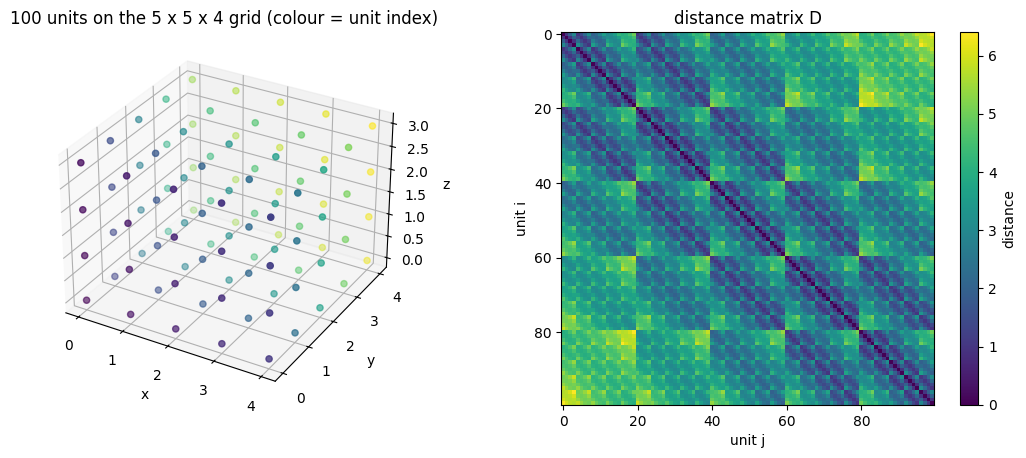

penalty on an orthogonal W:  seRNN 12.191  |  L1 5.289


In [20]:
# seRNN regulariser [DEMO cell 21]
regu_sernn = SE1_sWc(se1=GAMMA_SERNN)
# L1 regulariser [CAPSULE recording_decoding_demo, cell 8]
regu_l1 = tf.keras.regularizers.L1(GAMMA_L1)

# Unit positions: unit k sits at (x, y, z) = coords[k]
coords = np.stack(regu_sernn.coordinates, axis=1)       # (100, 3)
D = regu_sernn.distance_matrix                         # (100, 100), D[i, j] = Euclidean distance between units i and j
print("coords", coords.shape, "| first units:", coords[:5].tolist())
print("D", D.shape, "| symmetric:", np.allclose(D, D.T), "| diagonal = 0:", np.all(np.diag(D) == 0),
      f"| off-diagonal min {D[D > 0].min():.2f}, max {D.max():.2f}")

fig = plt.figure(figsize=(11, 4.5))
# Left: the grid. (The demo's visualise_neuron_structure draws an empty figure with recent matplotlib.)
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], c=np.arange(100), cmap='viridis')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('100 units on the 5 x 5 x 4 grid (colour = unit index)')
# Right: the distance matrix
ax = fig.add_subplot(1, 2, 2)
im = ax.imshow(D, cmap='viridis')
fig.colorbar(im, ax=ax, label='distance')
ax.set_xlabel('unit j'); ax.set_ylabel('unit i'); ax.set_title('distance matrix D')
plt.tight_layout(); plt.show()

# Sanity check: both penalties on a matrix like the network's initial W_rec (orthogonal)
W0 = tf.keras.initializers.Orthogonal(seed=0)((N_UNITS, N_UNITS))
print(f"penalty on an orthogonal W:  seRNN {float(regu_sernn(W0)):.3f}  |  L1 {float(regu_l1(W0)):.3f}")

#### Block 5 — Model

Same network as the demo [DEMO cells 21 + 23], for both groups. Only the regulariser on `W_rec` changes.

- `GaussianNoise(0.05)`: noise on the inputs, active during training only.
- `SimpleRNN(100)`: ReLU, orthogonal init of `W_rec`. Update rule: h_t = ReLU(W_in x_t + W_rec h_{t-1} + b).
- `Dense(4, softmax)`: one output per direction, read once at the last time step.
- Adam (default parameters, lr 0.001), cross-entropy loss.

Keras stores the recurrent weights as `recurrent_kernel[pre, post]`. We use `W_rec = recurrent_kernel.T`, so that `W_rec[i, j]` = weight from unit j to unit i.

In [21]:
# [DEMO cells 21 + 23] the demo's model, wrapped in a function so both groups use the same code
def make_model(recurrent_regularizer):
    model = tf.keras.models.Sequential([
        tf.keras.layers.GaussianNoise(stddev=INPUT_NOISE_STD),
        tf.keras.layers.SimpleRNN(N_UNITS, activation='relu', recurrent_initializer='orthogonal',
                                  return_sequences=False, recurrent_regularizer=recurrent_regularizer),
        tf.keras.layers.Dense(N_OUT, activation='softmax')
    ])
    model.build(input_shape=example_data[0].shape)
    model.compile(optimizer=tf.keras.optimizers.Adam(), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

tf.keras.backend.clear_session()
model_sernn = make_model(regu_sernn)
model_l1 = make_model(regu_l1)
model_sernn.summary()

# Weights of the RNN layer (layer 1): input weights, recurrent kernel, bias
W_in, K, b = model_sernn.layers[1].get_weights()
W_rec = K.T
print("W_in", W_in.shape, "| recurrent_kernel", K.shape, "| b", b.shape)
print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))
print("regulariser on the RNN layer:  seRNN", type(model_sernn.layers[1].recurrent_regularizer).__name__,
      "| L1", type(model_l1.layers[1].recurrent_regularizer).__name__)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gaussian_noise (GaussianNoise)  │ (128, 50, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (128, 100)             │        10,900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (128, 4)               │           404 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,304 (44.16 KB)

 Trainable params: 11,304 (44.16 KB)

 Non-trainable params: 0 (0.00 B)

W_in (8, 100) | recurrent_kernel (100, 100) | b (100,)
W_rec orthogonal at init: True
regulariser on the RNN layer:  seRNN SE1_sWc | L1 L1


/var/folders/nm/r91q1s2d6tvd_75pz9l1yl800000gn/T/ipykernel_98074/3188947228.py:22: RuntimeWarning: divide by zero encountered in matmul
  print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))
/var/folders/nm/r91q1s2d6tvd_75pz9l1yl800000gn/T/ipykernel_98074/3188947228.py:22: RuntimeWarning: overflow encountered in matmul
  print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))
/var/folders/nm/r91q1s2d6tvd_75pz9l1yl800000gn/T/ipykernel_98074/3188947228.py:22: RuntimeWarning: invalid value encountered in matmul
  print("W_rec orthogonal at init:", np.allclose(W_rec @ W_rec.T, np.eye(N_UNITS), atol=1e-5))


#### Block 6 — Train the 10 + 10 networks

One network per seed of `SEEDS` (block 2): 10 seRNN, 10 L1. Before each model, all seeds (python, numpy, TF) are reset to that seed.

- Accuracy = fraction of the 16 problems answered correctly, each problem once, without input noise. > 0.9 means at least 15/16. Every network must pass (checked).
- The seed lists come from first_draft Phase B (first 10 passing seeds per group). The weights obtained here are identical to Phase B, so its compression results can be reproduced.
- Networks are saved to `outputs/networks/` (W_in, W_rec, b, W_out, b_out, accuracy curves), so later blocks never retrain.

Time: about 3.5 s per network, ~1 min 10 in total.

In [22]:
# The 16 problems, each once, without noise: the set used for the > 90 % criterion
X16 = np.stack(gen.mazesdf['Problem_Vec']).reshape(16, GOAL_STEPS + DELAY_STEPS + CHOICE_STEPS, 8).astype('float32')
Y16 = np.stack(gen.mazesdf['Step_Encoded']).astype('float32')

def accuracy16(model):
    """Fraction of the 16 problems answered correctly (GaussianNoise is off outside training)."""
    return float(np.mean(model.predict(X16, verbose=0).argmax(1) == Y16.argmax(1)))

def train(seed, regu):
    """Train one network from a seed."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)          # python, numpy and TF seeds
    model = make_model(regu)
    history = model.fit(tfdf, epochs=EPOCHS, validation_data=tfdf_test, verbose=0)
    return model, history.history

def get_weights(model):
    W_in, K, b = model.layers[1].get_weights()
    W_out, b_out = model.layers[2].get_weights()
    return dict(W_in=W_in, W_rec=K.T, b=b, W_out=W_out, b_out=b_out)   # W_rec = recurrent_kernel.T (block 5)

os.makedirs(f"{OUT_DIR}/networks", exist_ok=True)
REGULARISERS = {'seRNN': regu_sernn, 'L1': regu_l1}
results = []
for group, regu in REGULARISERS.items():
    for seed in SEEDS[group]:
        model, hist = train(seed, regu)
        acc = accuracy16(model)
        np.savez(f"{OUT_DIR}/networks/{group}_seed{seed}.npz", **get_weights(model), acc16=acc,
                 accuracy=hist['accuracy'], val_accuracy=hist['val_accuracy'], loss=hist['loss'])
        results.append(dict(group=group, seed=seed, acc16=acc))
        print(f"{group:5s} seed {seed:2d}   accuracy {acc:.4f} ({round(acc * 16)}/16)")

results = pd.DataFrame(results)
results.to_csv(f"{OUT_DIR}/networks/accuracy.csv", index=False)
assert (results.acc16 > ACC_MIN).all(), results[results.acc16 <= ACC_MIN]
print(f"\nall {len(results)} networks pass {ACC_MIN}")

/Users/leandreramos/Desktop/work/Personal/Research/NeuroAI/MorphoAI/Spatial_Compressibility/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1794358393.353816 17555285 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is n

seRNN seed  2   accuracy 1.0000 (16/16)
seRNN seed  5   accuracy 0.9375 (15/16)


E0000 00:00:1794358401.102635 17555285 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed  7   accuracy 1.0000 (16/16)
seRNN seed 10   accuracy 1.0000 (16/16)


E0000 00:00:1794358408.837400 17555285 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


seRNN seed 11   accuracy 0.9375 (15/16)
seRNN seed 13   accuracy 0.9375 (15/16)


... (10 outputs left out)

E0000 00:00:1794358451.974595 17555285 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


L1    seed 12   accuracy 0.9375 (15/16)
L1    seed 13   accuracy 0.9375 (15/16)


E0000 00:00:1794358458.819879 17555285 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


L1    seed 18   accuracy 0.9375 (15/16)
L1    seed 19   accuracy 0.9375 (15/16)

all 20 networks pass 0.9
